In [1]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

X, y = make_moons(
    n_samples=500,
    noise=0.25,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [2]:
model = keras.Sequential([
    layers.Input(shape=(2,)),

    layers.Dense(256, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(256, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [3]:
history = model.fit(
    X_train,
    y_train,
    epochs=200,
    validation_data=(X_test, y_test),
    verbose=0
)

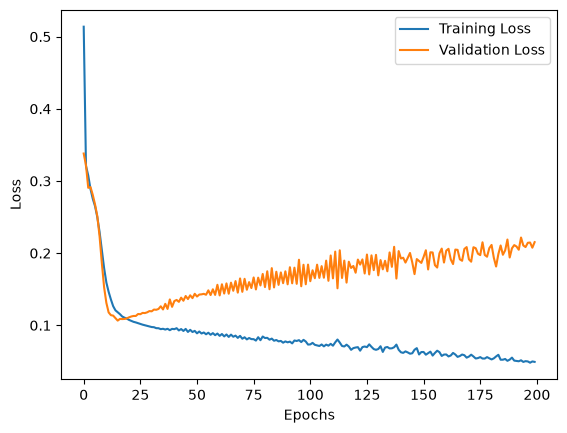

In [5]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

model = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train,
    y_train,
    epochs=200,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping],
    verbose=0
)

print("Training completed!")
print("Epochs used:", len(history.history["loss"]))